In [1]:
from pathlib import Path
import pandas as pd
import optuna
from optuna.storages import JournalStorage, JournalFileStorage

LOG_FILE = Path("./hp_search.log")

storage = JournalStorage(JournalFileStorage(str(LOG_FILE)))
study = optuna.load_study(study_name="prob_mlp_hp_search", storage=storage)

print(f"Trials completed : {len(study.trials)}")
print(f"Best val MSE     : {study.best_value:.6f}")
print(f"Best params      : {study.best_params}")

Trials completed : 75
Best val MSE     : 0.000024
Best params      : {'n_layers': 4, 'hidden_dim': 64, 'lr': 0.003713925796263049, 'batch_size': 1024, 'dropout': 0.0}


/home/samir/Desktop/WORK/f1tenth_gym_ws/venv/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/tmp/ipykernel_328104/574621968.py:8: FutureWarning: JournalFileStorage has been deprecated in v4.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v4.0.0. Use :class:`~optuna.storages.journal.JournalFileBackend` instead.
  storage = JournalStorage(JournalFileStorage(str(LOG_FILE)))


In [2]:
df = study.trials_dataframe()

# Keep only useful columns and rename for clarity
param_cols = [c for c in df.columns if c.startswith("params_")]
keep = ["number", "value", "state", "duration"] + param_cols
df = df[keep].rename(columns={
    "number": "trial",
    "value":  "val_mse",
    **{c: c.replace("params_", "") for c in param_cols}
})

# Sort by val_mse ascending (best first), show only completed trials
df_done = df[df["state"] == "COMPLETE"].sort_values("val_mse").reset_index(drop=True)
df_done

,trial,val_mse,state,duration,batch_size,dropout,hidden_dim,lr,n_layers
0,72,0.000024,COMPLETE,0 days 00:00:07.240018,1024,0.0,64,0.003714,4
1,57,0.000026,COMPLETE,0 days 00:00:08.315575,1024,0.0,64,0.003558,4
2,53,0.000027,COMPLETE,0 days 00:00:06.833531,1024,0.0,64,0.005280,4
3,56,0.000031,COMPLETE,0 days 00:00:07.437603,1024,0.0,64,0.005335,4
4,71,0.000033,COMPLETE,0 days 00:00:05.814694,1024,0.0,64,0.005804,4
5,49,0.000035,COMPLETE,0 days 00:00:06.601127,1024,0.0,64,0.002352,4
6,35,0.000037,COMPLETE,0 days 00:00:09.568041,512,0.0,32,0.006428,4
7,73,0.000040,COMPLETE,0 days 00:00:04.148069,1024,0.0,64,0.009742,4
8,21,0.000041,COMPLETE,0 days 00:00:08.675577,512,0.0,32,0.009679,3
9,23,0.000041,COMPLETE,0 days 00:00:12.830510,512,0.0,32,0.003231,3


In [3]:
# Top 10 trials
df_done.head(10)

,trial,val_mse,state,duration,batch_size,dropout,hidden_dim,lr,n_layers
0,72,0.000024,COMPLETE,0 days 00:00:07.240018,1024,0.0,64,0.003714,4
1,57,0.000026,COMPLETE,0 days 00:00:08.315575,1024,0.0,64,0.003558,4
2,53,0.000027,COMPLETE,0 days 00:00:06.833531,1024,0.0,64,0.005280,4
3,56,0.000031,COMPLETE,0 days 00:00:07.437603,1024,0.0,64,0.005335,4
4,71,0.000033,COMPLETE,0 days 00:00:05.814694,1024,0.0,64,0.005804,4
5,49,0.000035,COMPLETE,0 days 00:00:06.601127,1024,0.0,64,0.002352,4
6,35,0.000037,COMPLETE,0 days 00:00:09.568041,512,0.0,32,0.006428,4
7,73,0.000040,COMPLETE,0 days 00:00:04.148069,1024,0.0,64,0.009742,4
8,21,0.000041,COMPLETE,0 days 00:00:08.675577,512,0.0,32,0.009679,3
9,23,0.000041,COMPLETE,0 days 00:00:12.830510,512,0.0,32,0.003231,3


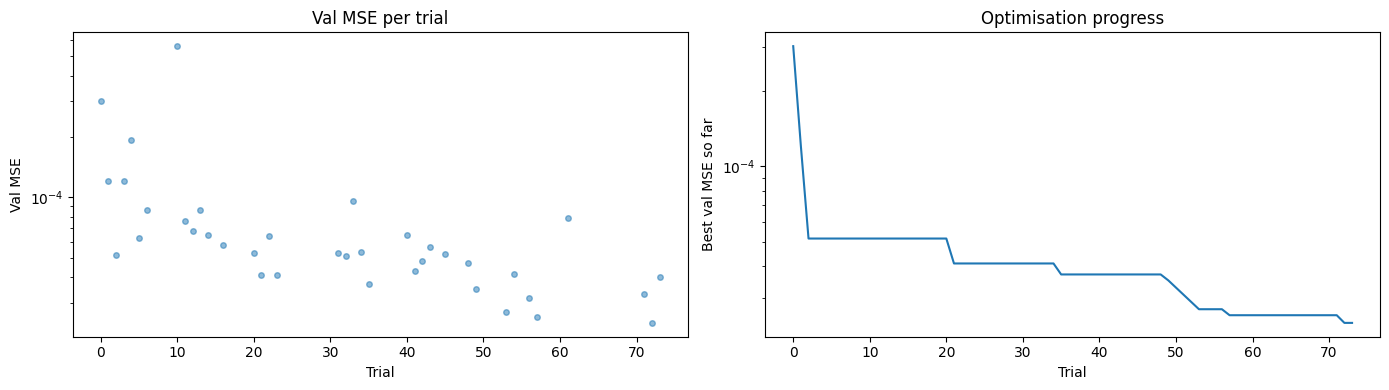

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Val MSE over trials
axes[0].plot(df_done["trial"], df_done["val_mse"], "o", alpha=0.5, markersize=4)
axes[0].set_xlabel("Trial")
axes[0].set_ylabel("Val MSE")
axes[0].set_title("Val MSE per trial")
axes[0].set_yscale("log")

# Best val MSE over time (running minimum)
ordered = df.loc[df["state"] == "COMPLETE"].sort_values("trial")
axes[1].plot(ordered["trial"], ordered["val_mse"].cummin(), "-")
axes[1].set_xlabel("Trial")
axes[1].set_ylabel("Best val MSE so far")
axes[1].set_title("Optimisation progress")
axes[1].set_yscale("log")

plt.tight_layout()
plt.show()

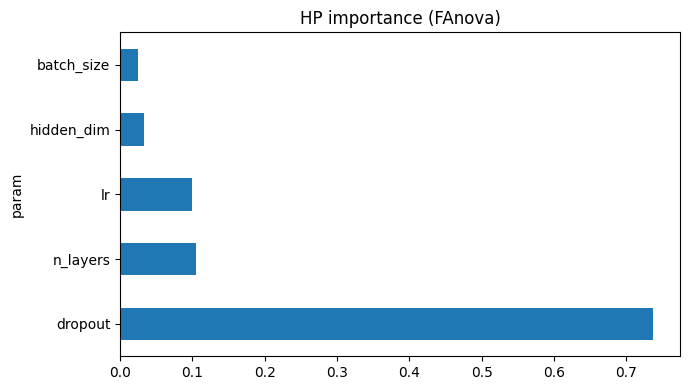

,param,importance
0,dropout,0.737335
1,n_layers,0.105380
2,lr,0.099830
3,hidden_dim,0.033186
4,batch_size,0.024269


In [5]:
# Parameter importance
importances = optuna.importance.get_param_importances(study)
imp_df = pd.DataFrame(importances.items(), columns=["param", "importance"]).sort_values("importance", ascending=False)

imp_df.plot(kind="barh", x="param", y="importance", legend=False,
            title="HP importance (FAnova)", figsize=(7, 4))
plt.tight_layout()
plt.show()
imp_df